# 01 · Explore the data
Loads the cached Metrica sample matches (run `python scripts/prepare.py` once first), plots a frame on the pitch, and shows the event-derived possession labels.

In [1]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from possession import data, labels, baseline, features, model, evaluate as ev

In [2]:
names = data.cached_matches(); print(names)
m = data.load(names[0])
y = labels.frame_labels(m.frame, m.period, m.events)
print(m.n_frames, "frames @", m.fps, "fps |", m.home.shape[1], "home /", m.away.shape[1], "away player slots")
print("label share (none, home, away):", np.round(np.bincount(y, minlength=3) / len(y), 3))
m.events.head(10)

['sample_game_1', 'sample_game_2', 'sample_game_3']


145006 frames @ 25.0 fps | 14 home / 14 away player slots
label share (none, home, away): [0.378 0.332 0.29 ]


,team,type,subtype,period,start_frame,end_frame
0,away,SET PIECE,KICK OFF,1,1,1
1,away,PASS,,1,1,3
2,away,PASS,,1,3,17
3,away,PASS,,1,45,61
4,away,PASS,,1,77,96
5,away,PASS,,1,191,217
6,away,PASS,,1,279,303
7,away,BALL LOST,INTERCEPTION,1,346,380
8,home,RECOVERY,INTERCEPTION,1,378,378
9,home,BALL LOST,INTERCEPTION,1,378,452


## One frame on the pitch
Coordinates are metres with the origin at the centre spot.

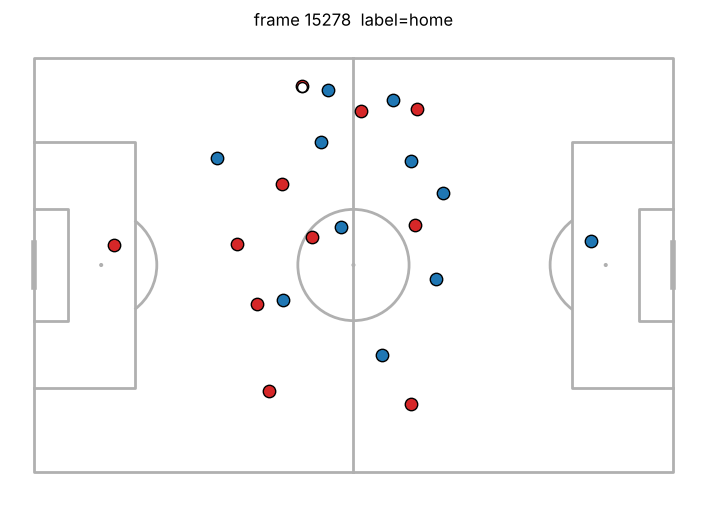

In [3]:
from mplsoccer import Pitch

from matplotlib.axes import Axes

def show_frame(m, i, ax: Axes | None = None) -> Axes:
    pitch = Pitch(pitch_type="custom", pitch_length=105, pitch_width=68, line_zorder=1)
    if ax is None:
        _, ax = plt.subplots(figsize=(9, 6))
    pitch.draw(ax=ax)
    # mplsoccer custom pitch has origin bottom-left
    off = np.array([52.5, 34])
    for P, c in ((m.home, "tab:red"), (m.away, "tab:blue")):
        pts = P[i] + off
        ax.scatter(pts[:, 0], pts[:, 1], c=c, s=80, edgecolors="k", zorder=3)
    if not np.isnan(m.ball[i, 0]):
        ax.scatter(*(m.ball[i] + off), c="white", edgecolors="k", s=50, zorder=4)
    ax.set_title(f"frame {m.frame[i]}  label={labels.CLASS_NAMES[y[i]]}")
    return ax

show_frame(m, int(np.flatnonzero(y == labels.HOME)[3000]));

## Possession timeline
First 3 minutes: event-derived labels vs. whether the ball is tracked. In this public sample, the ball is NaN whenever play is dead. That's a leak real tracking won't have, which is why `evaluate.degrade_ball` exists.

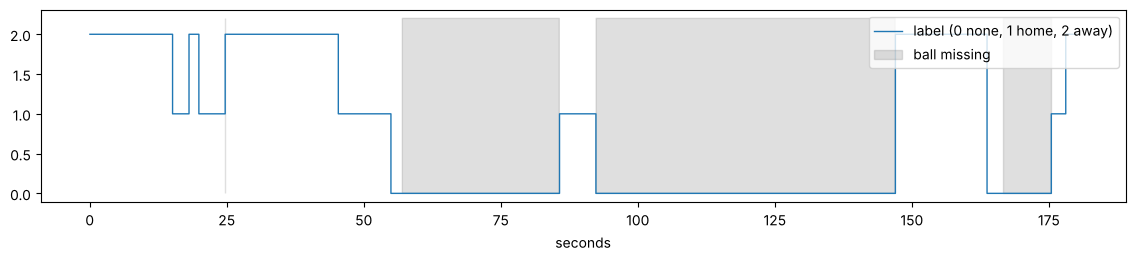

In [4]:
s = slice(0, 25 * 180)
t = m.frame[s] / m.fps
fig, ax = plt.subplots(figsize=(14, 2.5))
ax.step(t, y[s], where="post", lw=1, label="label (0 none, 1 home, 2 away)")
ax.fill_between(t, 0, 2.2, where=np.isnan(m.ball[s, 0]), color="grey", alpha=.25, step="post", label="ball missing")
ax.set_xlabel("seconds"); ax.legend(loc="upper right"); plt.show()

## Distance from each team's nearest player to the ball

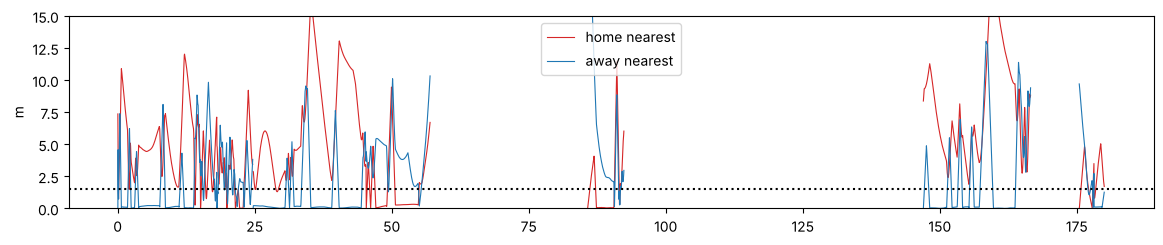

In [5]:
dh, da = baseline.team_distances(m)
fig, ax = plt.subplots(figsize=(14, 2.5))
ax.plot(t, dh[s, 0], c="tab:red", lw=.8, label="home nearest")
ax.plot(t, da[s, 0], c="tab:blue", lw=.8, label="away nearest")
ax.axhline(1.5, c="k", ls=":"); ax.set_ylim(0, 15); ax.set_ylabel("m"); ax.legend(); plt.show()